# XGBoost (from scratch)

Gradient boosting (`22_gradient_boosting`, `23_gradient_boosting_classifier`) taken to second order, plus regularization. Each sample has a **gradient** `g` and a **hessian** `h` of the loss at the current prediction:

| objective | `g` | `h` |
|---|---|---|
| squared error | `pred − y` | `1` |
| logistic | `p − y` | `p(1 − p)` |

For a leaf containing a set of samples with `G = Σg`, `H = Σh`, the loss-minimizing weight and its quality score are:

```
w = −G / (H + λ)            score = G² / (H + λ)
```

A split is accepted only if it improves the total score by more than the price `γ` of an extra leaf:

```
gain = ½ · [ score_left + score_right − score_parent ] − γ
```

What this adds over plain gradient boosting:

- **`reg_lambda` (λ):** L2 penalty on leaf weights → smaller, safer updates.
- **`gamma` (γ):** minimum gain to split → built-in pruning; a large γ gives a constant model.
- **`min_child_weight`:** minimum Σh in a child → stops splits on tiny, noisy groups.
- **Newton step:** using `h` makes each tree a better step than the plain gradient.

Missing from the real library (listed in the code): row/column subsampling, histogram splits, missing-value handling, multiclass, GPU/parallelism. The demo compares against the real `xgboost` when it is installed (optional), otherwise against scikit-learn.

## Usage

```python
# (the class is defined in the Implementation section below)

reg = XGBoost("reg:squarederror", n_estimators=100, learning_rate=0.3, max_depth=3).fit(X_train, y_train)
clf = XGBoost("binary:logistic", reg_lambda=1.0, gamma=0.1).fit(X_train, y_train)
preds, probs = clf.predict(X_test), clf.predict_proba(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class _XGBTree:
    """One XGBoost tree. Every sample carries a gradient g and a hessian h of the loss. For a leaf
    holding a set of samples with sums G = sum(g), H = sum(h):

        best leaf weight   w = -G / (H + lambda)
        score of the leaf     G^2 / (H + lambda)        (higher = better fit)
        gain of a split       0.5 * (score_left + score_right - score_parent) - gamma

    lambda shrinks leaf weights (L2 regularization); gamma is the price of adding a leaf, so
    splits that don't improve the loss by more than gamma are never made (built-in pruning)."""

    def __init__(self, max_depth, reg_lambda, gamma, min_child_weight):
        self.max_depth = max_depth
        self.reg_lambda = reg_lambda
        self.gamma = gamma
        self.min_child_weight = min_child_weight

    def fit(self, X, g, h):
        self.root = self._grow(X, g, h, 0)
        return self

    def predict(self, X):
        return self._predict(self.root, X)

    def _grow(self, X, g, h, depth):
        lam = self.reg_lambda
        G, H = g.sum(), h.sum()
        leaf = -G / (H + lam)
        if depth >= self.max_depth or len(g) < 2:
            return leaf

        best_gain, best_feature, best_threshold = 0.0, None, None
        for f in range(X.shape[1]):
            order = np.argsort(X[:, f])
            xs = X[order, f]
            GL, HL = np.cumsum(g[order])[:-1], np.cumsum(h[order])[:-1]
            GR, HR = G - GL, H - HL
            gain = 0.5 * (GL**2 / (HL + lam) + GR**2 / (HR + lam) - G**2 / (H + lam)) - self.gamma
            valid = (xs[1:] != xs[:-1]) & (HL >= self.min_child_weight) & (HR >= self.min_child_weight)
            gain = np.where(valid, gain, -np.inf)
            i = gain.argmax()
            if gain[i] > best_gain:
                best_gain, best_feature, best_threshold = gain[i], f, (xs[i] + xs[i + 1]) / 2

        if best_feature is None:
            return leaf
        mask = X[:, best_feature] <= best_threshold
        return (best_feature, best_threshold,
                self._grow(X[mask], g[mask], h[mask], depth + 1),
                self._grow(X[~mask], g[~mask], h[~mask], depth + 1))

    def _predict(self, node, X):
        if not isinstance(node, tuple):
            return np.full(len(X), node)
        feature, threshold, left, right = node
        mask = X[:, feature] <= threshold
        out = np.empty(len(X))
        out[mask] = self._predict(left, X[mask])
        out[~mask] = self._predict(right, X[~mask])
        return out


def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


class XGBoost:
    """XGBoost-style gradient boosting: second-order (Newton) optimization with a regularized
    objective. Compared with plain gradient boosting it (1) uses the hessian as well as the
    gradient, (2) penalizes leaf weights (reg_lambda) and leaf count (gamma), and (3) prunes
    splits whose gain is not worth it.

    objective: "reg:squarederror" (g = pred - y, h = 1)
               "binary:logistic"  (g = p - y,    h = p(1 - p); labels any two values)

    ponytail: exact greedy split search only; no subsampling, column sampling or histogram
    binning, no missing-value handling, no multiclass."""

    def __init__(self, objective="reg:squarederror", n_estimators=100, learning_rate=0.3, max_depth=3,
                 reg_lambda=1.0, gamma=0.0, min_child_weight=1.0):
        self.objective = objective
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.reg_lambda = reg_lambda
        self.gamma = gamma
        self.min_child_weight = min_child_weight

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        if self.objective == "binary:logistic":
            self.classes_, y = np.unique(y, return_inverse=True)
            if len(self.classes_) != 2:
                raise ValueError("binary:logistic needs exactly 2 classes")
            p0 = y.mean()
            self.base_score = np.log(p0 / (1 - p0))  # prior as log-odds
        elif self.objective == "reg:squarederror":
            y = np.asarray(y, dtype=float)
            self.base_score = y.mean()
        else:
            raise ValueError(f"unknown objective: {self.objective}")

        F = np.full(len(y), self.base_score)
        self.trees = []
        for _ in range(self.n_estimators):
            if self.objective == "binary:logistic":
                p = _sigmoid(F)
                g, h = p - y, p * (1 - p)
            else:
                g, h = F - y, np.ones_like(y)
            tree = _XGBTree(self.max_depth, self.reg_lambda, self.gamma, self.min_child_weight)
            F += self.learning_rate * tree.fit(X, g, h).predict(X)
            self.trees.append(tree)
        return self

    def _raw(self, X):
        X = np.asarray(X, dtype=float)
        F = np.full(len(X), self.base_score)
        for tree in self.trees:
            F += self.learning_rate * tree.predict(X)
        return F

    def predict_proba(self, X):
        p = _sigmoid(self._raw(X))
        return np.column_stack([1 - p, p])

    def predict(self, X):
        if self.objective == "binary:logistic":
            return self.classes_[(self._raw(X) > 0).astype(int)]
        return self._raw(X)

## See it work

### 1. Regularisation: `reg_lambda` smooths the leaves

XGBoost's twist over plain gradient boosting is a **regularised objective** and a second-order (Newton) step: the leaf value is `w = −G/(H + λ)`. A larger `λ` shrinks every leaf value toward zero, so the fit gets smoother and less sensitive to noise. Same data, three values of `λ` (30 trees, depth 4):

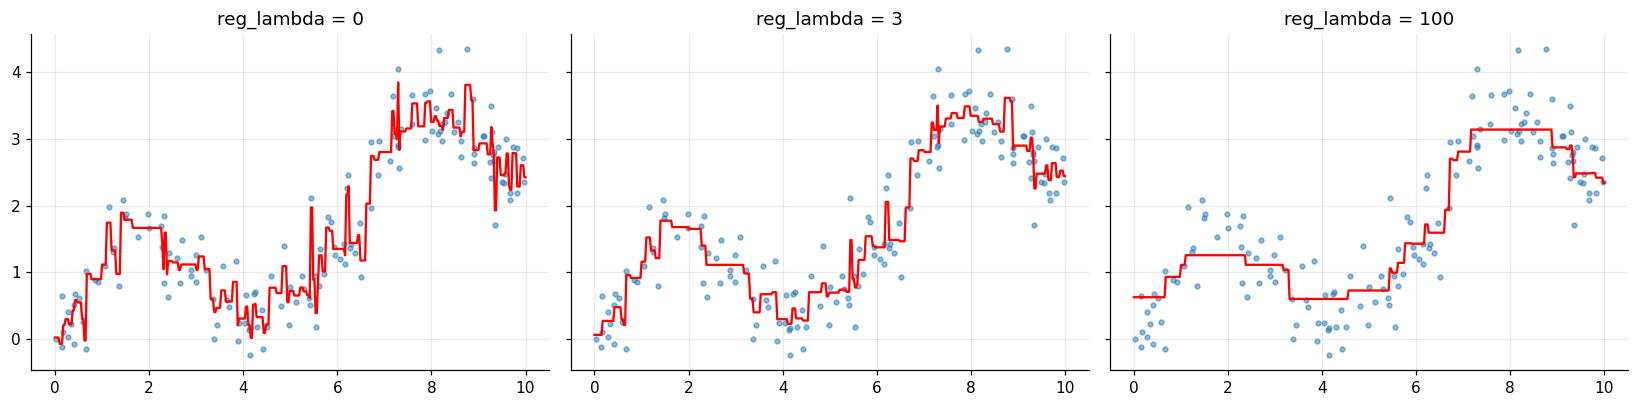

In [3]:
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 10, 150)); y = np.sin(x) + 0.3 * x + rng.normal(scale=0.4, size=150)
xs = np.linspace(0, 10, 400)[:, None]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, lam in zip(axes, [0.0, 3.0, 100.0]):
    m = XGBoost("reg:squarederror", n_estimators=30, learning_rate=0.3, max_depth=4, reg_lambda=lam).fit(x[:, None], y)
    ax.scatter(x, y, s=10, alpha=0.5); ax.plot(xs, m.predict(xs), "r"); ax.set_title(f"reg_lambda = {lam:g}")
plt.tight_layout(); plt.show()

### 2. `gamma` and `min_child_weight`: stop splitting early

A split is only made if its **gain** exceeds `gamma` (a per-split penalty), and only if each child has enough total hessian (`min_child_weight`, roughly "enough samples"). Both prune the tree, giving simpler models. Compare how rough the fits are:

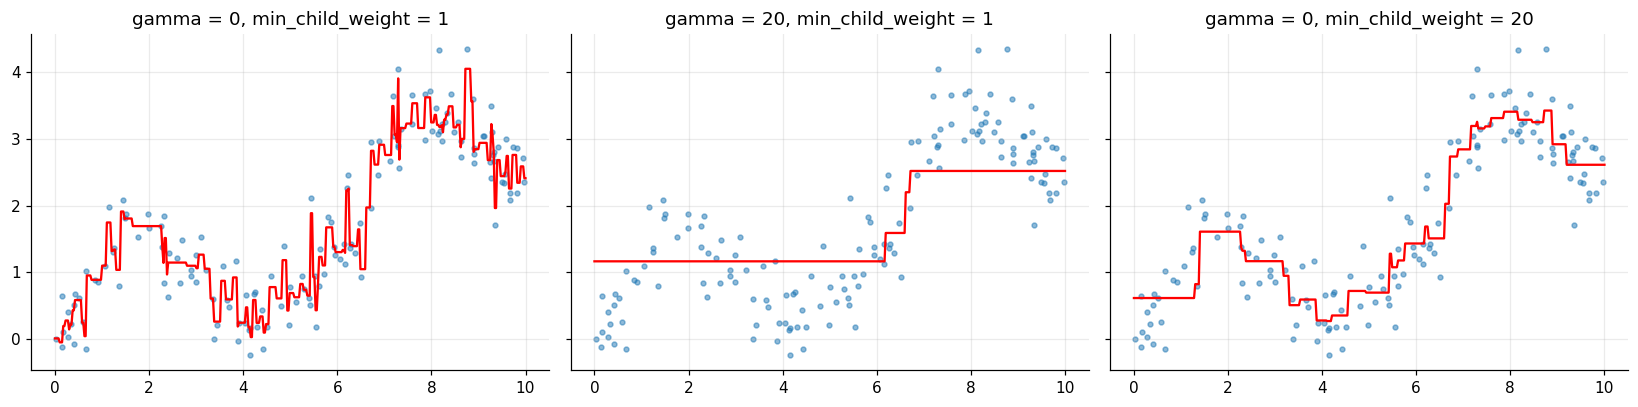

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (g, mcw) in zip(axes, [(0.0, 1.0), (20.0, 1.0), (0.0, 20.0)]):
    m = XGBoost("reg:squarederror", n_estimators=30, learning_rate=0.3, max_depth=6, gamma=g, min_child_weight=mcw).fit(x[:, None], y)
    ax.scatter(x, y, s=10, alpha=0.5); ax.plot(xs, m.predict(xs), "r"); ax.set_title(f"gamma = {g:g}, min_child_weight = {mcw:g}")
plt.tight_layout(); plt.show()

### 3. Classification with the logistic objective

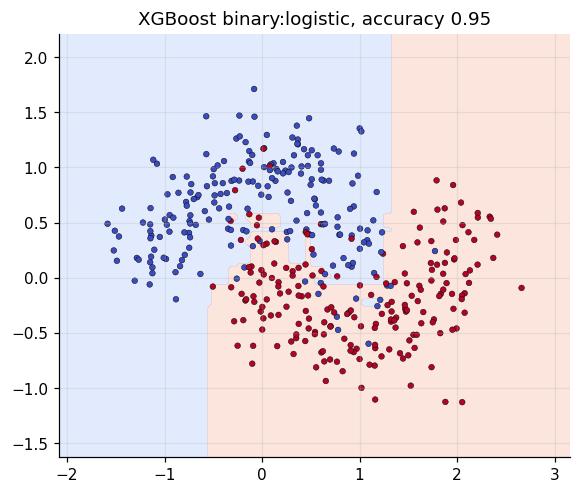

In [5]:
from sklearn.datasets import make_moons
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)

Xm, ym = make_moons(n_samples=400, noise=0.3, random_state=0)
m = XGBoost("binary:logistic", n_estimators=60, learning_rate=0.2, max_depth=3).fit(Xm, ym)
fig, ax = plt.subplots(figsize=(6, 5)); plot_boundary(ax, m, Xm, ym, n=120); ax.set_title(f"XGBoost binary:logistic, accuracy {(m.predict(Xm) == ym).mean():.2f}"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from sklearn.datasets import load_breast_cancer, make_friedman1
from sklearn.model_selection import train_test_split

PARAMS = dict(n_estimators=100, learning_rate=0.3, max_depth=3)

# --- regression ---
X, y = make_friedman1(n_samples=500, noise=1.0, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
ours = XGBoost("reg:squarederror", **PARAMS).fit(X_train, y_train)
mse_ours = np.mean((ours.predict(X_test) - y_test) ** 2)

try:
    import xgboost as xgb  # optional: pip install xgboost to compare against the real library

    theirs = xgb.XGBRegressor(**PARAMS, tree_method="exact", base_score=float(y_train.mean())).fit(X_train, y_train)
    mse_theirs = np.mean((theirs.predict(X_test) - y_test) ** 2)
    print("regression test MSE: ours=%.4f xgboost=%.4f" % (mse_ours, mse_theirs))
    assert abs(mse_ours - mse_theirs) / mse_theirs < 0.05
except ImportError:
    from sklearn.ensemble import GradientBoostingRegressor

    theirs = GradientBoostingRegressor(n_estimators=100, learning_rate=0.3, max_depth=3, random_state=0).fit(X_train, y_train)
    mse_theirs = np.mean((theirs.predict(X_test) - y_test) ** 2)
    print("regression test MSE: ours=%.4f sklearn GBR=%.4f  (xgboost not installed)" % (mse_ours, mse_theirs))
    assert abs(mse_ours - mse_theirs) / mse_theirs < 0.15

# --- binary classification ---
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.3, random_state=42)
ours = XGBoost("binary:logistic", **PARAMS).fit(X_train, y_train)
acc_ours = (ours.predict(X_test) == y_test).mean()
try:
    p0 = float(y_train.mean())
    theirs = xgb.XGBClassifier(**PARAMS, tree_method="exact", base_score=p0).fit(X_train, y_train)
    acc_theirs = (theirs.predict(X_test) == y_test).mean()
    print("breast cancer accuracy: ours=%.4f xgboost=%.4f" % (acc_ours, acc_theirs))
    assert abs(acc_ours - acc_theirs) < 0.03
except NameError:
    print("breast cancer accuracy: ours=%.4f" % acc_ours)
    assert acc_ours > 0.93

regression test MSE: ours=2.8170 xgboost=2.8170


breast cancer accuracy: ours=0.9708 xgboost=0.9766


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def _tiny():
    return np.array([[1.0], [2.0], [3.0], [4.0]]), np.array([1.0, 1.0, 3.0, 3.0])


def test_leaf_weight_matches_the_formula():
    # base score = mean = 2, so g = pred - y = [1, 1, -1, -1], h = 1.
    # Left leaf: G = 2, H = 2  ->  w = -G / (H + lambda) = -2/3 for lambda = 1.
    X, y = _tiny()
    model = XGBoost(n_estimators=1, learning_rate=1.0, max_depth=1, reg_lambda=1.0).fit(X, y)
    assert np.allclose(model.predict(X), [2 - 2 / 3, 2 - 2 / 3, 2 + 2 / 3, 2 + 2 / 3])


def test_lambda_shrinks_the_update():
    X, y = _tiny()
    small = XGBoost(n_estimators=1, learning_rate=1.0, max_depth=1, reg_lambda=0.0).fit(X, y).predict(X)
    large = XGBoost(n_estimators=1, learning_rate=1.0, max_depth=1, reg_lambda=100.0).fit(X, y).predict(X)
    assert np.allclose(small, y)                      # lambda = 0: leaves hit the exact mean
    assert np.abs(large - 2.0).max() < 0.05           # heavy L2: barely moves from the base score


def test_gamma_prunes_unprofitable_splits():
    X, y = _tiny()
    model = XGBoost(n_estimators=5, learning_rate=1.0, max_depth=3, gamma=100.0).fit(X, y)
    assert np.allclose(model.predict(X), 2.0)         # no split worth gamma: the model stays constant


def test_binary_logistic():
    rng = np.random.default_rng(0)
    X = rng.uniform(-1, 1, size=(300, 2))
    y = np.where(X[:, 0] * X[:, 1] > 0, "pos", "neg")  # XOR pattern
    model = XGBoost(objective="binary:logistic", n_estimators=50, max_depth=3).fit(X, y)
    assert (model.predict(X) == y).mean() > 0.95
    probs = model.predict_proba(X)
    assert np.allclose(probs.sum(axis=1), 1.0) and ((probs > 0) & (probs < 1)).all()

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_leaf_weight_matches_the_formula
PASS test_lambda_shrinks_the_update
PASS test_gamma_prunes_unprofitable_splits
PASS test_binary_logistic

all 4 tests passed


## Takeaways

- **Use it** as the go-to for tabular competitions and industry problems: fast, regularised, handles missing values (in the real library), strong out of the box.
- **What is different from `22`/`23`:** (1) it uses both the gradient `g` and the hessian `h` of the loss (a Newton step), (2) the objective includes `γ` per leaf and `½λ‖w‖²`, giving the split gain `½(G_L²/(H_L+λ) + G_R²/(H_R+λ) − G²/(H+λ)) − γ` and leaf weight `−G/(H+λ)`, (3) engineering: column/row subsampling, histogram splits, parallelism (not in this version).
- **Interview line:** *"Gradient boosting with a second-order approximation of a regularised objective; split gain and leaf values come from `G`, `H`, `λ`, `γ`."*